# Final project: one MobileNetV2 normalization experiment
Final evaluation: **3 November 2026**

Completed baseline: Xception clean accuracy **93.67%**, versus the paper's **95.27%**. Original audited macro-F1: Xception **0.9176**, MobileNetV2 **0.7372**. The original hypothesis was **not supported**.

Change only MobileNetV2 normalization from `[0,1]` to `[-1,1]`. Keep the crop, audited split, seed, head, full backbone fine-tuning, Adam, batch size and five epochs unchanged.

**Exploratory target:** improve over original MobileNetV2 and come within **0.02** macro-F1 of audited Xception with fewer parameters. This reuses a previously evaluated test set, so it is exploratory, not independent confirmation. The original outcome remains unchanged.

**Setup:** select **T4 GPU and runtime 2026.07 (Python 3.12)**. Upload `brain_mri_final_source.zip` using the Files sidebar. The last cell exports code, results **and the trained weights**.

Sources: [MobileNetV2 preprocessing](https://www.tensorflow.org/api_docs/python/tf/keras/applications/mobilenet_v2/preprocess_input), [Colab runtime versions](https://research.google.com/colaboratory/runtime-version-faq.html).

**Verified outcome:** the follow-up reaches **81.92% accuracy**, macro-F1 **0.8062**. This improves over original audited MobileNetV2, but the remaining **0.1114** Xception gap exceeds the **0.02** target. The exploratory target is **not met**. Imported weights support local prediction; Mac CPU scores differ from saved Colab probabilities.

In [1]:
import os
import subprocess
import sys
from pathlib import Path
from zipfile import ZipFile

IN_COLAB = Path("/content").exists() and "google.colab" in sys.modules
if IN_COLAB:
    if sys.version_info[:2] not in [(3, 11), (3, 12)]:
        raise RuntimeError(
            "Select runtime 2026.07 (Python 3.12) and T4 GPU under Runtime > Change runtime type, reconnect and rerun."
        )
    ROOT = Path("/content/final_brain_mri")
    bundle = Path("/content/brain_mri_final_source.zip")
    if not (ROOT / "configs/mobilenet_imagenet.yaml").exists():
        if not bundle.exists():
            raise FileNotFoundError("Upload brain_mri_final_source.zip in the Colab Files sidebar.")
        with ZipFile(bundle) as archive:
            for item in archive.infolist():
                if not (ROOT / item.filename).resolve().is_relative_to(ROOT.resolve()):
                    raise ValueError("Unsafe archive path")
            archive.extractall(ROOT)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")]
    )
else:
    ROOT = next(
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "configs/mobilenet_imagenet.yaml").exists()
    )
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("KERAS_HOME", str(ROOT / ".cache/keras"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(ROOT / ".cache"))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
print("Project:", ROOT)

Project: /Users/manuchaudhary/ComputerVision_Prj


## 1. Settings
Normalization is inside the saved model. This experiment tests whether it helps; it does not assume why the original model underperformed.

In [2]:
import pandas as pd
from IPython.display import Image, display

from src.reproduction.config import load_config

RUN_TRAINING = IN_COLAB  # False for reviewing stored results locally.
CONFIG = load_config(ROOT / "configs/mobilenet_imagenet.yaml")
RUN_DIR = ROOT / "outputs/final_project/leakage_audited/MobileNetV2"
display(pd.Series(CONFIG))
if RUN_TRAINING:
    import tensorflow as tf

    print("Devices:", tf.config.list_physical_devices())
    if IN_COLAB:
        assert tf.config.list_physical_devices("GPU"), "Select T4 GPU."

dataset                 masoudnickparvar/brain-tumor-mri-dataset
dataset_version                                                1
data_dir                                                data/raw
output_dir                                 outputs/final_project
seed                                                          42
protocol                                         leakage_audited
class_names            [glioma, meningioma, no_tumor, pituitary]
models                                             [MobileNetV2]
image_size                                                   128
batch_size                                                    20
epochs                                                         5
learning_rate                                             0.0001
blur_kernel                                                    5
threshold                                                     45
trainable_backbone                                          True
input_scaling            

## 2. Preserved baseline
These are earlier measured scores, separate from the new run.

In [3]:
baseline = pd.read_csv(ROOT / "results/disci2025/summary.csv")
display(
    baseline[baseline.evaluation_view == "clean"][
        ["model", "protocol", "accuracy", "macro_f1", "total_parameters"]
    ]
)

,model,protocol,accuracy,macro_f1,total_parameters
0,MobileNetV2,leakage_audited,0.742944,0.737228,4880068
1,Xception,leakage_audited,0.917620,0.917584,25056428
2,MobileNetV2,paper_based,0.720824,0.679837,4880068
4,Xception,paper_based,0.936690,0.935414,25056428


## 3. One five-epoch run
Pinned dataset version 1. Audited split: **4,518 train / 798 validation / 1,311 test**. Only training receives augmentation. Final-epoch weights are used. Interrupted runs restart; `--resume` skips verified complete checkpoints.

In [4]:
if RUN_TRAINING:
    subprocess.check_call([sys.executable, "scripts/final_project.py", "train", "--resume"])
else:
    print("Training disabled. No new performance claim without completed evidence.")

Training disabled. No new performance claim without completed evidence.


## 4. Verified comparison
Recompute metrics from predictions and require normalization to be the only shared setting changed. Different hardware may still affect comparison with the earlier run.

experiment                                         MobileNetV2 ImageNet normalization only
accuracy                                                                          0.819222
macro_f1                                                                            0.8062
original_mobile_macro_f1                                                          0.737228
audited_xception_macro_f1                                                         0.917584
macro_f1_improvement                                                              0.068972
xception_minus_new_macro_f1                                                       0.111384
allowed_margin                                                                        0.02
total_parameters                                                                   4880068
meets_exploratory_target                                                             False
same_data_and_other_settings                                                          True

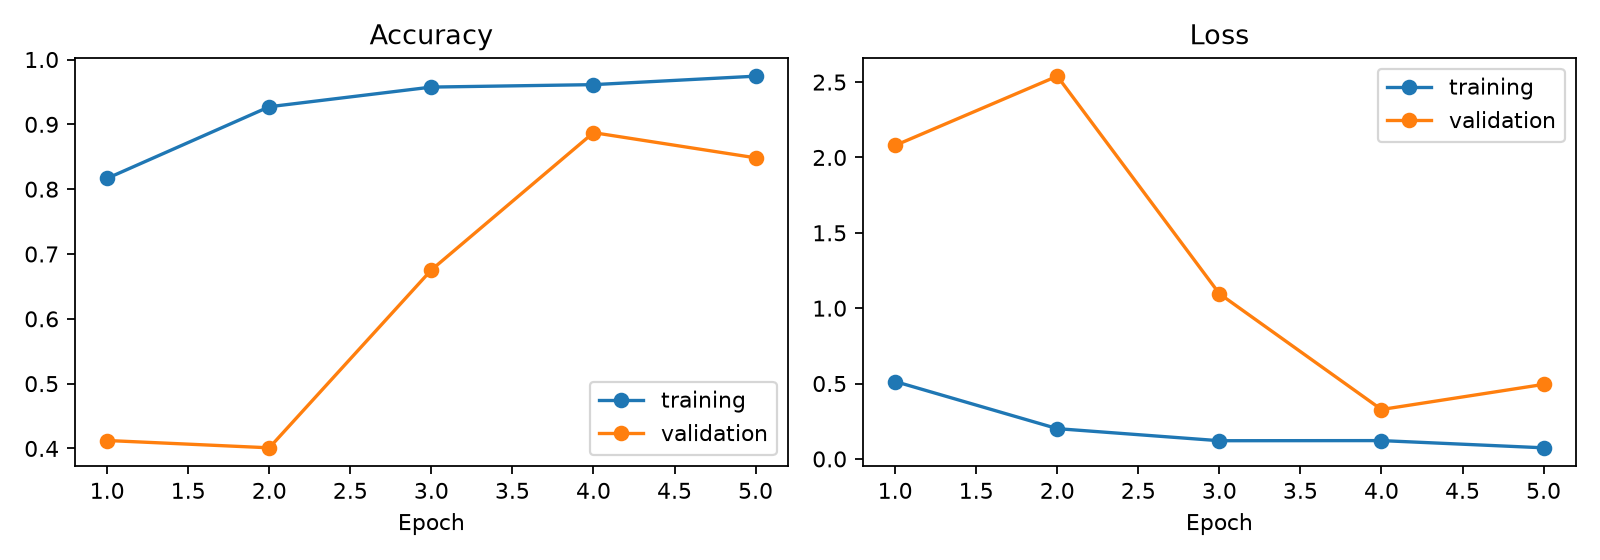

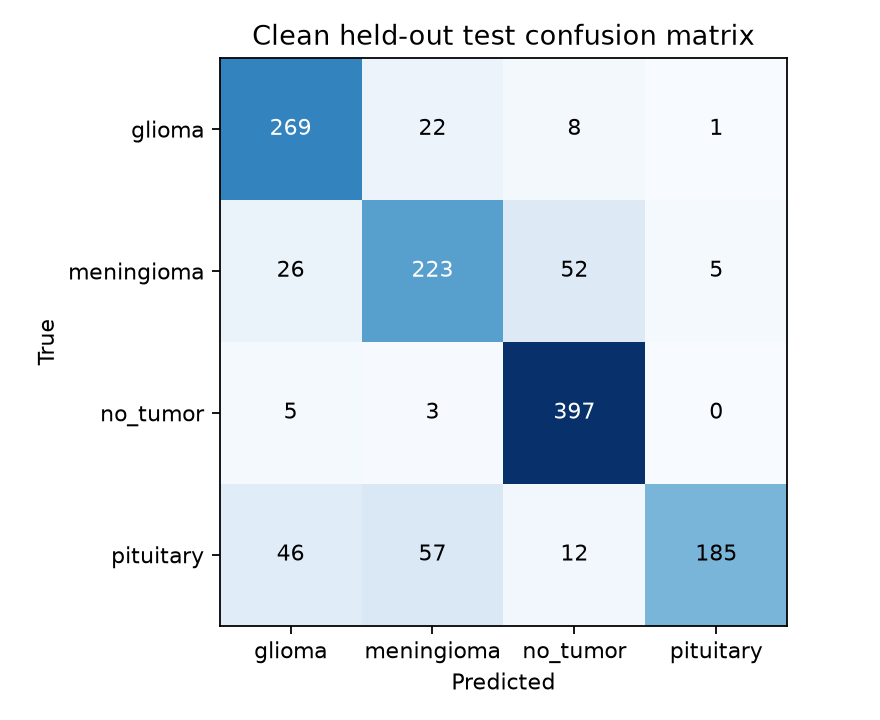

In [5]:
from src.reproduction.final_project import save_comparison

EVIDENCE_DIR = (
    RUN_DIR
    if (RUN_DIR / "metadata.json").exists()
    else ROOT / "results/final_project/runs/leakage_audited/MobileNetV2"
)
if (EVIDENCE_DIR / "metadata.json").exists():
    comparison = save_comparison(EVIDENCE_DIR, ROOT / "results/final_project")
    display(pd.Series(comparison))
    for filename in ["learning_curves.png", "confusion_matrix.png"]:
        display(Image(filename=str(EVIDENCE_DIR / filename), width=750))
else:
    print("New experiment pending. Complete training before reporting new scores.")

## 5. Fresh-image prediction
Uses saved weights and the exact training crop. Do not normalize twice. Leave `DEMO_IMAGE` empty for a labeled test image, or use an uploaded JPG/PNG path. Softmax scores are not calibrated medical probabilities.

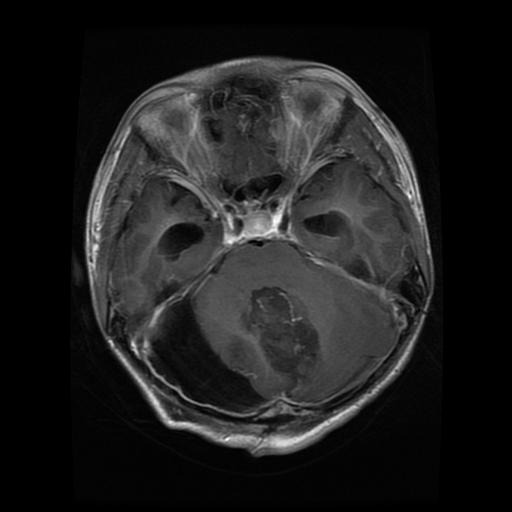

Known dataset label: glioma


Predicted class: glioma


glioma        9.966694e-01
meningioma    7.864927e-05
no_tumor      3.251973e-03
pituitary     1.745972e-08
Name: Softmax scores, dtype: float64

Model softmax scores are not calibrated diagnostic probabilities.


In [6]:
from src.reproduction.final_project import predict_image

DEMO_IMAGE = ""  # Example: /content/my_mri.jpg
if (RUN_DIR / "model.keras").exists():
    if not IN_COLAB and not RUN_TRAINING:
        import tensorflow as tf

        tf.config.set_visible_devices([], "GPU")
    test = pd.read_csv(RUN_DIR / "test_manifest.csv")
    image = Path(DEMO_IMAGE) if DEMO_IMAGE else ROOT / "data/raw" / test.iloc[0].path
    if image.exists():
        display(Image(filename=str(image), width=280))
        if not DEMO_IMAGE:
            print("Known dataset label:", test.iloc[0].class_name)
        prediction = predict_image(RUN_DIR, image)
        print("Predicted class:", prediction["predicted_class"])
        display(pd.Series(prediction["scores"], name="Softmax scores"))
        print(prediction["note"])
    else:
        print("Choose an existing image. Exports exclude raw MRI images.")
else:
    print("Complete training or restore the full demo bundle to load weights.")

## 6. Export for the evaluation
Download this ZIP **before disconnecting Colab**. It contains code, baseline evidence, new results, configuration and `.keras` weights, without the raw dataset. On the Mac, extract into a separate folder and run `python scripts/final_project.py predict --image /path/to/mri.jpg`.

Explain: the baseline, original unsupported hypothesis, one normalization change, actual follow-up results and fresh-image inference. Limits remain one seed, missing patient IDs, duplicate test images and unresolved perceptual matches. Do not claim exact paper replication, tumor segmentation or clinical validity.

In [7]:
from scripts.package_final import package_final

if (RUN_DIR / "model.keras").exists():
    destination = (
        Path("/content/brain_mri_final_demo.zip")
        if IN_COLAB
        else ROOT / "deliverables/brain_mri_final_demo.zip"
    )
    archive = package_final(destination, include_model=True)
    if IN_COLAB:
        from google.colab import files

        files.download(str(archive))
else:
    print("No trained model to export yet.")

Saved /Users/manuchaudhary/ComputerVision_Prj/deliverables/brain_mri_final_demo.zip (57,572,804 bytes)
